# NSBI analysis — Asimov vs median of toys (from-scratch redo, 2026-07-16)

**Question.** Does the Asimov dataset predict the median result of an ensemble of toy
pseudo-experiments for the *unbinned* (event-by-event) analysis of off-shell
$gg \to H^* \to ZZ \to 4\ell$ — and how much of any discrepancy is caused by the neural
density-ratio estimate rather than by the statistics of the low event count? This half of the
study was never reproduced before today; the histogram half is `histogram_reproduction.ipynb`
(definitions of the statistic and of the comparison are identical and are restated briefly here).

**Three versions of the same likelihood are compared, on the same events and the same toys:**

| name | density ratio | what it isolates |
|---|---|---|
| `nsbi-exact` | exact, from the stored matrix elements | the statistics of the low event count alone (an NSBI analysis with a perfect network) |
| `nsbi-nn` | Tae's `sbi_over_bkg` network + a `sig_over_bkg` trained by us with **Tae's exact recipe** (his architecture, data, hyperparameters, seed) | the full network-based analysis |
| `nsbi-nn (sig exact)` | Tae's `sbi_over_bkg` network + exact $r_{\rm sig/bkg}$ | the contribution of the `sbi_over_bkg` network alone |
| `nsbi-nn (3×128 sig)` | Tae's `sbi_over_bkg` network + the 3×128 `sig_over_bkg` (same validation loss as the Tae-recipe one to 3·10⁻⁵) | whether the distortion depends on the *particular* network or only on its loss |

**Events**: Tae's own test split (576 265 SBI events, sum of weights $= 5.6565$ fb $=$ the SBI
cross-section), downloaded 2026-07-16 from his CERNBox share together with the checkpoints.
**Toys**: 2000 per luminosity point, per-event Poisson fluctuation of the weights at
$\mu_{\rm true}=1$, one random stream per toy, master seed 42.
**Grid**: $\mu \in [0,4]$, 161 points. **Luminosities**: $\{1, 10, 30, 100, 140, 200, 300, 500,
700, 1000, 3000\}$ fb$^{-1}$. All scans computed by `../scripts/asimov_scan.py`.

**Writing rule.** Every quantity is defined before it is used, in standard statistics terms.
"CCGV" = Cowan, Cranmer, Gross, Vitells, *Eur. Phys. J. C* 71 (2011) 1554, arXiv:1007.1727.

## 1. Definitions

**The likelihood.** Every event is treated as its own Poisson-distributed bin: with per-event
counts $k_i$ (a toy) and a model predicting $f_i(\mu) = w_i(\mu)\,L$ events at event $i$,

$$-2\ln L(\mu) = 2\sum_i\left[f_i(\mu) - k_i\ln f_i(\mu)\right] + \text{const}.$$

This is the extended unbinned likelihood (the event-count term is the $\sum_i f_i = \nu(\mu)L$
piece — it is **included**; Tae's committed code omitted it, see §7). For `nsbi-exact` the
per-event weight at any $\mu$ comes from the stored matrix elements,
$w_i(\mu) = w_i\,[\mu\,\mathrm{msq}_{\rm sig} + \sqrt{\mu}\,\mathrm{msq}_{\rm int} +
\mathrm{msq}_{\rm bkg}]_i/\mathrm{msq}_{{\rm sbi},i}$ — exact by construction, so the Asimov best
fit must be $\mu = 1$ to machine precision (it is, at all 11 luminosities).

For the network versions the same likelihood is written with the density ratio
$r(x|\mu) = p(x|\mu)/p_{\rm bkg}(x)$, composed from the two SM-point ratios exactly as in Tae's
notebook:

$$r(x|\mu) = \frac{\sigma_{\rm sig}(\mu-\sqrt{\mu})\,r_{\rm sig/bkg}(x) + \sigma_{\rm sbi}\sqrt{\mu}\,r_{\rm sbi/bkg}(x) + \sigma_{\rm bkg}(1-\sqrt{\mu})}{\sigma_{\rm sig}\mu + \sigma_{\rm int}\sqrt{\mu} + \sigma_{\rm bkg}},$$

plus the event-count term $2[\nu(\mu)L - N\ln(\nu(\mu)L)]$ with $\nu(\mu)$ from the
cross-section table.

**The statistic and the comparison** (identical to the histogram notebook): per toy,
$t(\mu) = -2[\ln L(\mu) - \ln L(\hat\mu)]$ with $\hat\mu$ that toy's best fit on the $\mu \ge 0$
grid. In the large-sample limit $t(\mu)$ follows a noncentral $\chi^2_1$ distribution with
noncentrality $\Lambda(\mu) = t_A(\mu)$ (the Asimov curve). The test: measured median and 16%/84%
quantiles of $t(\mu)$ across toys vs the quantiles of that predicted distribution, at every $\mu$.
Consequences worth restating: the median of $t$ at $\mu_{\rm true}$ is predicted to be 0.455 (not
0), and the median-of-$t$ curve is predicted $1.185\times$ wider than the Asimov curve — both
verified on ideal likelihoods in the histogram notebook's self-test. Limitations: the prediction
assumes no parameter boundary (the fraction of toys at $\hat\mu = 0$ is printed everywhere), and
$\hat\mu$ is quantised to the grid step 0.025.

In [1]:
import os, sys, json, csv, pickle
import numpy as np
import torch
import matplotlib.pyplot as plt

ROOT = os.path.abspath(os.path.join(os.getcwd(), '..'))
if not os.path.isdir(os.path.join(ROOT, 'scripts')):
    ROOT = os.getcwd()
sys.path.insert(0, os.path.join(ROOT, 'scripts'))
from asimov_scan import (t_curves, crossing_interval, toy_quantiles, predicted_quantiles,
                         bootstrap_quantile_width_ratio)

LUMIS = [1, 10, 30, 100, 140, 200, 300, 500, 700, 1000, 3000]
SETS = {'nsbi-exact': 'output/asimov_scan/nsbi_exact_testsplit',
        'nsbi-nn': 'output/asimov_scan/nsbi_nn_taerecipe',
        'nsbi-nn (sig exact)': 'output/asimov_scan/nsbi_nn_sigexact',
        'nsbi-nn (3x128 sig)': 'output/asimov_scan/nsbi_nn',
        'hist': 'output/asimov_scan/hist'}
scans = {}
for name, rel in SETS.items():
    scans[name] = {}
    for L in LUMIS:
        d = os.path.join(ROOT, rel, f'lumi_{L}')
        scans[name][L] = dict(
            nll_asimov=torch.load(os.path.join(d, 'nll_asimov.pt'), map_location='cpu').numpy(),
            nll_toys=torch.load(os.path.join(d, 'nll_toys.pt'), map_location='cpu').numpy(),
            mu=torch.load(os.path.join(d, 'mu_scan.pt'), map_location='cpu').numpy())
mu = scans['nsbi-exact'][1]['mu']
I_MU1 = int(np.argmin(np.abs(mu - 1.0)))
H4L = os.path.join(ROOT, 'asimov-aymptotics-check/run/h4l')
print('loaded', {k: len(v) for k, v in scans.items()})

loaded {'nsbi-exact': 11, 'nsbi-nn': 11, 'nsbi-nn (sig exact)': 11, 'nsbi-nn (3x128 sig)': 11, 'hist': 11}


## 2. What Tae shared, and what his networks actually learned

The CERNBox share (token `Shv8zta4oZ1aOL4`, mirrored to `asimov-aymptotics-check/run/h4l/`)
contains, for each of `sig_over_bkg` and `sbi_over_bkg`: six checkpoints, the training
configuration (`config.yaml`, `hparams.yaml`), the epoch-by-epoch losses (`metrics.csv`), the
train/validation/test event splits, and the input scaler. Both networks are MLPs with 16 hidden
layers of 1024 nodes.

**The `sbi_over_bkg` puzzle.** Every shared `sbi_over_bkg` checkpoint file is labelled
val_loss $= 0.69 \approx \ln 2 = 0.6931$, the loss of a classifier that always answers "the two
classes are equally likely" — the same value at which our own two retraining attempts stalled,
which the project had been treating as a failed training. The matrix elements settle what a
perfect classifier could possibly achieve on this task: the cell below computes, from the exact
density ratio evaluated on Tae's own validation events, the *best achievable* value of his
balanced validation loss and the area under the ROC curve of the exact ratio.

/tmp/ipykernel_196079/486069946.py:11: RuntimeWarning: divide by zero encountered in divide
  raw_n = msq(ev_num, num_comp) / msq(ev_num, den_comp)
/tmp/ipykernel_196079/486069946.py:12: RuntimeWarning: divide by zero encountered in divide
  raw_d = msq(ev_den, num_comp) / msq(ev_den, den_comp)


/tmp/ipykernel_196079/486069946.py:12: RuntimeWarning: divide by zero encountered in divide
  raw_d = msq(ev_den, num_comp) / msq(ev_den, den_comp)


                   network  best achievable  achieved  margin captured  exact-ratio ROC area
    sbi_over_bkg (Tae, 4l)         0.692401  0.692582             76%                 0.513
sig_over_bkg (Tae's recipe, 4l)         0.411164  0.419194             97%                 0.892
sig_over_bkg (path B 3x128, 4l)         0.411164  0.419166             97%                 0.892


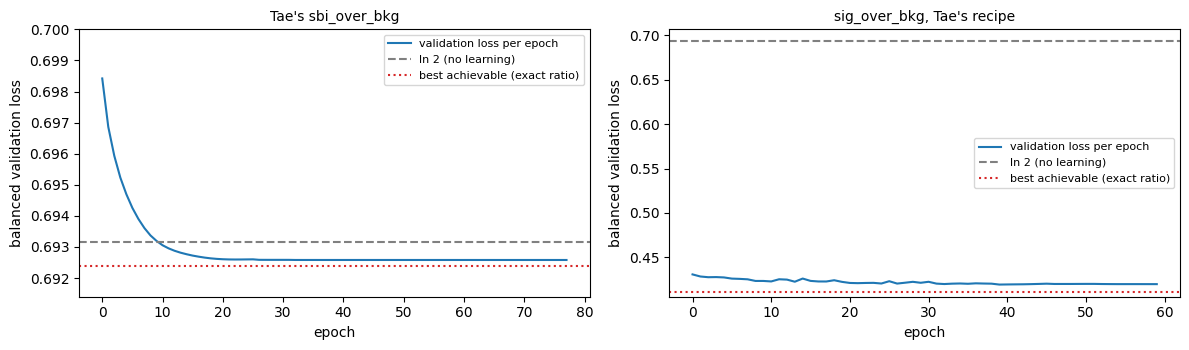

In [2]:
def msq(ev, c):
    return ev.components[f'msq_{c}_sm'].to_numpy(dtype=np.float64)

def optimal_loss_and_auc(ev_num, ev_den, num_comp, den_comp='bkg'):
    '''Best achievable balanced binary-cross-entropy and ROC area, from the exact ratio.
    The ratio of matrix elements is normalised on the denominator sample (weighted mean 1,
    the defining property of a density ratio). Events whose denominator matrix element
    underflows to zero are dropped (they carry < 1e-8 of the weight).'''
    w_n = np.clip(ev_num.weights.to_numpy(dtype=np.float64), 0, None)
    w_d = np.clip(ev_den.weights.to_numpy(dtype=np.float64), 0, None)
    raw_n = msq(ev_num, num_comp) / msq(ev_num, den_comp)
    raw_d = msq(ev_den, num_comp) / msq(ev_den, den_comp)
    ok_n, ok_d = np.isfinite(raw_n) & (raw_n > 0), np.isfinite(raw_d) & (raw_d > 0)
    raw_n, w_n, raw_d, w_d = raw_n[ok_n], w_n[ok_n], raw_d[ok_d], w_d[ok_d]
    c = np.average(raw_d, weights=w_d)
    loss = 0.5 * (np.average(np.log1p(c / raw_n), weights=w_n)
                  + np.average(np.log1p(raw_d / c), weights=w_d))
    r_all = np.concatenate([raw_n, raw_d])
    y = np.concatenate([np.ones_like(raw_n), np.zeros_like(raw_d)])
    w = np.concatenate([w_n / w_n.sum(), w_d / w_d.sum()])
    o = np.argsort(r_all); y, w = y[o], w[o]
    cum_bkg = np.cumsum(w * (1 - y))
    auc = float(np.sum(w * y * cum_bkg) / (np.sum(w * y) * np.sum(w * (1 - y))))
    return loss, auc

def best_val(metrics_csv):
    vals = [float(r['val_loss']) for r in csv.DictReader(open(metrics_csv)) if r.get('val_loss')]
    return min(vals), vals

def pkl(path):
    with open(path, 'rb') as f:
        return pickle.load(f)

ln2 = float(np.log(2))
rows = []
# Tae's sbi_over_bkg: 4l channel, correct artifact
opt, auc = optimal_loss_and_auc(pkl(f'{H4L}/sbi_over_bkg/events_numerator_val.pkl'),
                                pkl(f'{H4L}/sbi_over_bkg/events_denominator_val.pkl'), 'sbi')
ach, traj_sbi = best_val(f'{H4L}/sbi_over_bkg/lightning_logs/version_0/metrics.csv')
rows.append(('sbi_over_bkg (Tae, 4l)', opt, ach, auc))
# the sig_over_bkg actually used in the nsbi-nn scans below: trained by us with Tae's
# exact recipe (16 layers x 1024 nodes, lr 1e-4, batch 1024, seed 42, patience 20)
TR = os.path.join(ROOT, 'output/nsbi-pathB/h4l/sig_over_bkg_taerecipe')
opt, auc = optimal_loss_and_auc(pkl(f'{TR}/events_numerator_val.pkl'),
                                pkl(f'{TR}/events_denominator_val.pkl'), 'sig')
ach, traj_sig = best_val(f'{TR}/lightning_logs/version_0/metrics.csv')
rows.append(("sig_over_bkg (Tae's recipe, 4l)", opt, ach, auc))
# the earlier small stand-in, for the architecture comparison
PB = os.path.join(ROOT, 'output/nsbi-pathB/h4l/sig_over_bkg')
ach_pb, _ = best_val(f'{PB}/lightning_logs/version_0/metrics.csv')
rows.append(('sig_over_bkg (path B 3x128, 4l)', opt, ach_pb, auc))

print(f"{'network':>26} {'best achievable':>16} {'achieved':>9} {'margin captured':>16} {'exact-ratio ROC area':>21}")
for name, opt, ach, auc in rows:
    print(f'{name:>26} {opt:>16.6f} {ach:>9.6f} {(ln2-ach)/(ln2-opt):>15.0%} {auc:>21.3f}')

fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for ax, (traj, ttl, opt) in zip(axes, [(traj_sbi, "Tae's sbi_over_bkg", rows[0][1]),
                                       (traj_sig, "sig_over_bkg, Tae's recipe", rows[1][1])]):
    ax.plot(traj, '-', color='C0', label='validation loss per epoch')
    ax.axhline(ln2, color='grey', ls='--', label='ln 2 (no learning)')
    ax.axhline(opt, color='C3', ls=':', label='best achievable (exact ratio)')
    ax.set_xlabel('epoch'); ax.set_ylabel('balanced validation loss'); ax.set_title(ttl, fontsize=10)
    ax.legend(fontsize=8)
axes[0].set_ylim(rows[0][1] - 0.001, 0.70)
fig.tight_layout(); plt.show()

**Verdict on the "ln 2 floor".** The best achievable loss for SBI-vs-BKG classification is
itself only $7.5\times10^{-4}$ below $\ln 2$, because the two samples are genuinely
near-indistinguishable one event at a time (exact-ratio ROC area 0.513 — barely above the 0.5 of
pure guessing; the difference between SBI and BKG is a $\sim$5% yield deficit spread over the
whole spectrum, not a separable population). Tae's network in fact captured about three quarters
of that tiny margin. **Nobody's training failed** — the 2-decimal checkpoint filenames simply
cannot display learning at the $10^{-4}$ level. Our own "stalled at $\ln 2$" retraining attempts
were near-optimal too. This removes the "broken ingredient" suspicion from the checkpoints
themselves; what the networks *cannot* do is deliver the ratio to the sub-percent pointwise
accuracy that the unbinned likelihood turns out to require (§5-§6).

**One genuine problem with the shared material** (evidence:
`run/h4l/sig_over_bkg/lightning_logs/version_0/config.yaml`): the shared `sig_over_bkg` was
trained on the **2ℓ2ν channel** — numerator/denominator paths `zz2l2v/ggZZ_{sig,bkg}` and a
10-feature input list containing `met`/`met_phi` — contradicting the 16-feature 4ℓ recipe in the
same share's `fit-carl-4l.sh`. It cannot process 4ℓ events (its scaler expects 10 inputs), so it
cannot be the network behind Tae's committed 300 fb$^{-1}$ scans, and a bit-exact reproduction of
those scans is **impossible with the shared material** (erratum table, §8). Checked the same day
against Tae's *dataset* share as well (token `AeKNoWslVzwmAdt`, full listing, 124 entries): it
holds the training CSVs of both channels and two sets of 48 observed pseudo-experiment CSVs at
$\mu = 0.4$ and $\mu = 2.5$ — **no checkpoints anywhere**; its `zz4l/ggZZ_*/analyzed.csv` are
byte-identical in size and header to the 4ℓ CSVs already local since 09 Jul. So no correctly
trained 4ℓ `sig_over_bkg` exists in any shared location.

**The missing network was therefore retrained by us with Tae's exact recipe** (approved by
Marta, 2026-07-16): his architecture (16 layers × 1024 nodes), learning rate $10^{-4}$, batch
1024, seed 42, early-stopping patience 20, on the same 4ℓ CSVs his fit script names
(condor cluster 5106594; 60 epochs, 2.2 GPU-hours; his config's `sample_size: 10^7` is a cap our
datamodule version lacks — a no-op, the CSVs hold fewer rows). Best validation loss **0.419194**,
statistically identical to the 3 × 128 network trained earlier in the week (0.419166), both
capturing 97% of the achievable margin — on this task the architecture is irrelevant, and the
remaining 3% of margin is not a capacity limit. The `nsbi-nn` scans below use this Tae-recipe
network. Note from §5–§6 that even a 97%-of-margin ratio still leaves visible likelihood-level
distortions: a loss within a few percent of optimal does not imply a negligible pointwise ratio
error — itself a finding about how demanding the unbinned likelihood is.

## 3. The measurement with the exact ratio: is the failure intrinsic?

Same panel layout as the histogram notebook: measured 16%/50%/84% quantiles of $t(\mu)$ across
the 2000 toys (blue), the Asimov curve (orange dashed), and the predicted quantiles (black
dotted, noncentral $\chi^2_1$ with $\Lambda = t_A(\mu)$). If the dramatic NSBI failure of Tae's
slide 7 were intrinsic to the unbinned likelihood at these event counts, it would appear here,
with the network removed from the problem entirely.

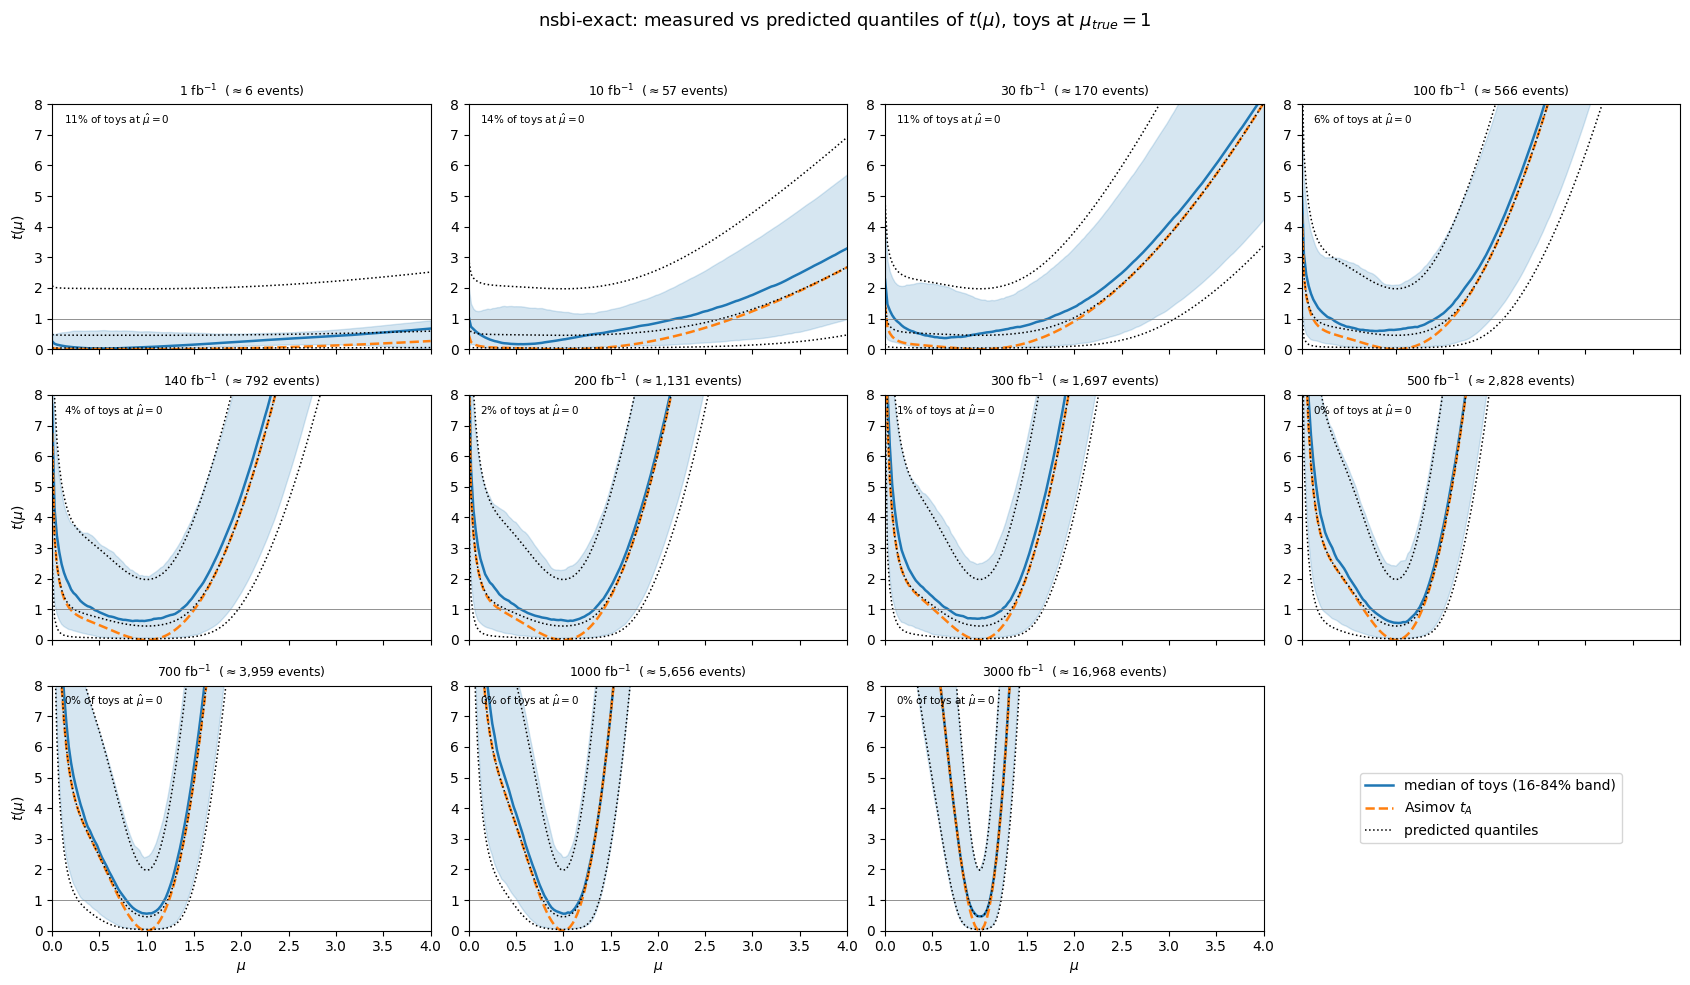

In [3]:
def panel_grid(name, ymax=8.0):
    fig, axes = plt.subplots(3, 4, figsize=(17, 10), sharex=True)
    out = {}
    for ax, L in zip(axes.ravel(), LUMIS):
        r = scans[name][L]
        t_toys, mu_hats = t_curves(r['nll_toys'], mu)
        t_asim, _ = t_curves(r['nll_asimov'], mu)
        q16, q50, q84 = toy_quantiles(t_toys)
        p16, p50, p84 = predicted_quantiles(t_asim)
        ax.fill_between(mu, q16, q84, alpha=0.18, color='C0')
        ax.plot(mu, q50, '-', color='C0', lw=1.8)
        ax.plot(mu, t_asim, '--', color='C1', lw=1.8)
        for p in (p16, p50, p84):
            ax.plot(mu, p, ':', color='k', lw=1.1)
        ax.axhline(1.0, color='grey', lw=0.6)
        ax.text(0.03, 0.92, f'{np.mean(mu_hats <= mu[1]):.0%} of toys at $\\hat\\mu=0$',
                transform=ax.transAxes, fontsize=7.5)
        ax.set_ylim(0, ymax); ax.set_xlim(mu[0], mu[-1])
        ax.set_title(f'{L:g} fb$^{{-1}}$  ($\\approx${5.656*L:,.0f} events)', fontsize=9)
        out[L] = (t_toys, t_asim, mu_hats)
    axes.ravel()[-1].axis('off')
    handles = [plt.Line2D([], [], color='C0', lw=1.8, label='median of toys (16-84% band)'),
               plt.Line2D([], [], color='C1', ls='--', lw=1.8, label='Asimov $t_A$'),
               plt.Line2D([], [], color='k', ls=':', lw=1.1, label='predicted quantiles')]
    axes.ravel()[-1].legend(handles=handles, loc='center', fontsize=10)
    for ax in axes[-1, :]: ax.set_xlabel('$\\mu$')
    for ax in axes[:, 0]: ax.set_ylabel('$t(\\mu)$')
    fig.suptitle(f'{name}: measured vs predicted quantiles of $t(\\mu)$, toys at $\\mu_{{true}}=1$', fontsize=13)
    fig.tight_layout(rect=[0, 0, 1, 0.96]); plt.show()
    return out

per_lumi_exact = panel_grid('nsbi-exact')

## 4. The same measurement with the network ratio

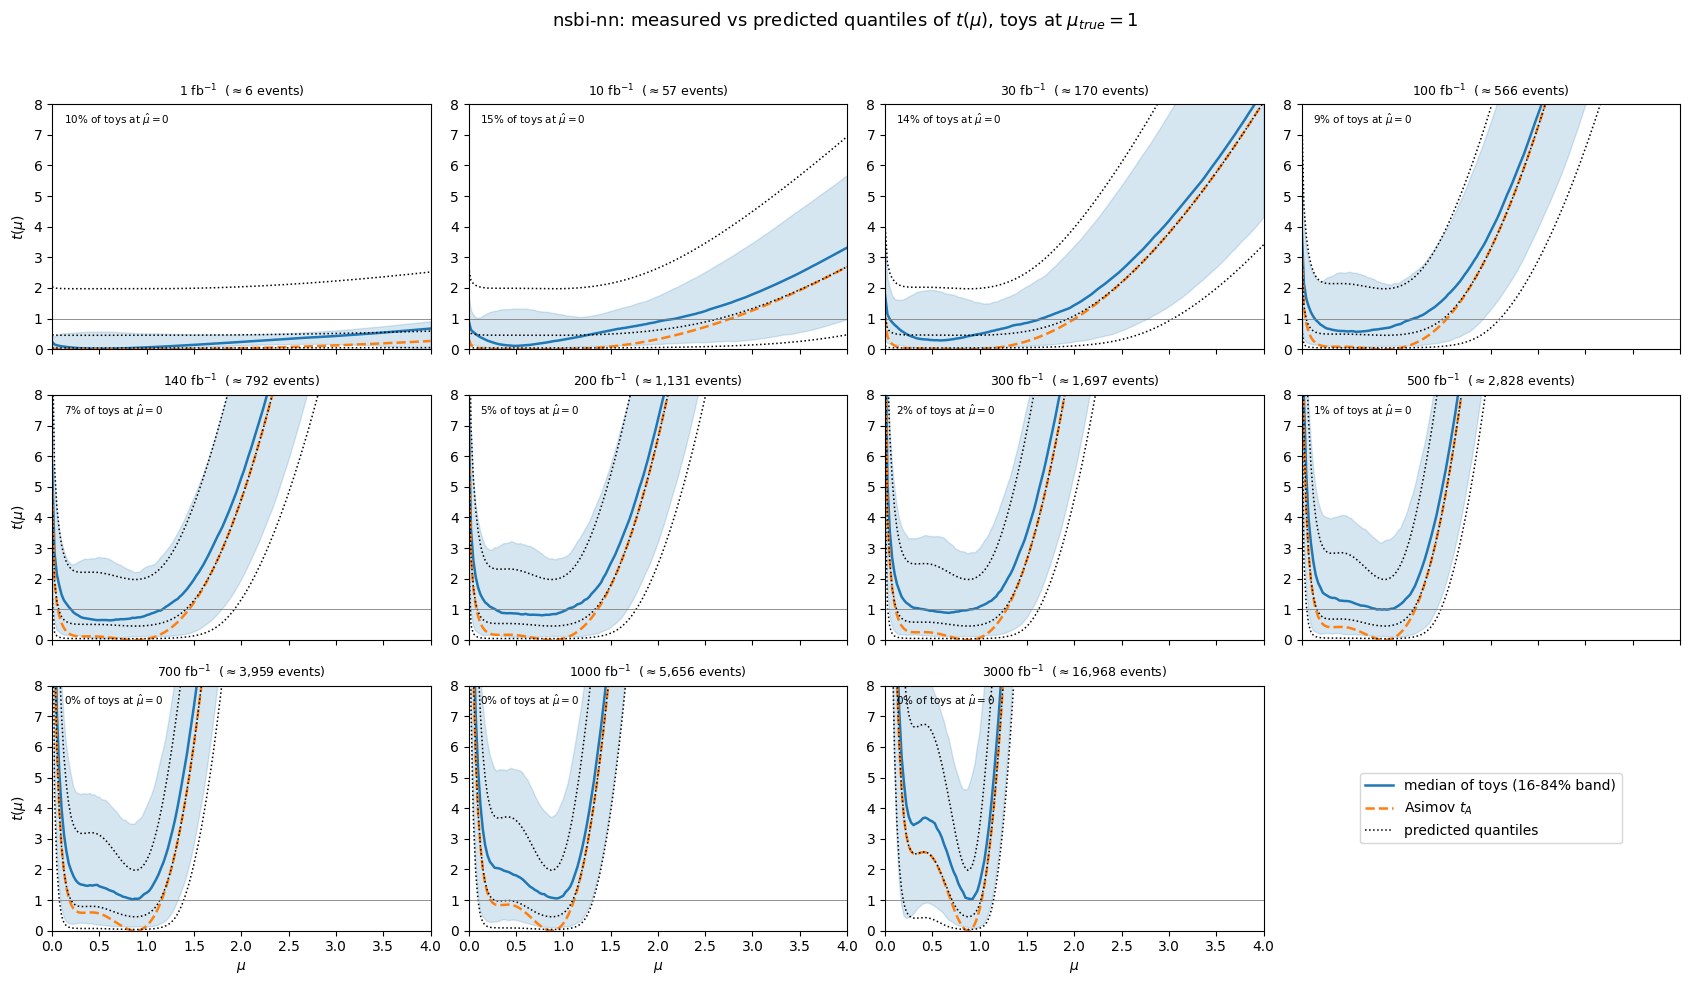

In [4]:
per_lumi_nn = panel_grid('nsbi-nn')

## 5. Summary tables and the cross-analysis picture

Columns as in the histogram notebook (§4 there): `r_med` is the width of the median-of-$t$ curve
measured from its own minimum at threshold 1, divided by the Asimov width — its large-sample
expectation is **1.185**; `t(1)med` is the measured median of $t$ at $\mu = 1$ (predicted 0.455);
`cover` is the fraction of toys whose 68% interval contains $\mu = 1$ (nominal 0.683); `at0` is
the fraction of toys with $\hat\mu = 0$.

In [5]:
def summarize(name, per_lumi):
    out = {}
    for L in LUMIS:
        t_toys, t_asim, mu_hats = per_lumi[L]
        _, _, w_a = crossing_interval(t_asim, mu)
        ratio, err = bootstrap_quantile_width_ratio(t_toys, t_asim, mu)
        q50 = np.quantile(t_toys, 0.5, axis=1)
        p50 = predicted_quantiles(t_asim, qs=(0.5,))[0]
        out[L] = dict(mu_A=float(mu[np.argmin(t_asim)]), med_mu=float(np.median(mu_hats)),
                      at0=float(np.mean(mu_hats <= mu[1])), w_A=w_a, ratio=ratio, ratio_err=err,
                      t1=float(q50[I_MU1]), cover=float(np.mean(t_toys[I_MU1] <= 1.0)),
                      maxdev=float(np.nanmax(np.abs(q50 - p50))))
    return out

per_lumi_nnsx = {L: (lambda r: (t_curves(r['nll_toys'], mu)[0], t_curves(r['nll_asimov'], mu)[0],
                                t_curves(r['nll_toys'], mu)[1]))(scans['nsbi-nn (sig exact)'][L])
                 for L in LUMIS}
per_lumi_hist = {L: (lambda r: (t_curves(r['nll_toys'], mu)[0], t_curves(r['nll_asimov'], mu)[0],
                                t_curves(r['nll_toys'], mu)[1]))(scans['hist'][L])
                 for L in LUMIS}
per_lumi_nn128 = {L: (lambda r: (t_curves(r['nll_toys'], mu)[0], t_curves(r['nll_asimov'], mu)[0],
                                 t_curves(r['nll_toys'], mu)[1]))(scans['nsbi-nn (3x128 sig)'][L])
                  for L in LUMIS}
tables = {'nsbi-exact': summarize('nsbi-exact', per_lumi_exact),
          'nsbi-nn': summarize('nsbi-nn', per_lumi_nn),
          'nsbi-nn (sig exact)': summarize('nsbi-nn (sig exact)', per_lumi_nnsx),
          'nsbi-nn (3x128 sig)': summarize('nsbi-nn (3x128 sig)', per_lumi_nn128),
          'hist': summarize('hist', per_lumi_hist)}

for name in ['nsbi-exact', 'nsbi-nn', 'nsbi-nn (sig exact)', 'nsbi-nn (3x128 sig)']:
    print(f'--- {name} ---')
    print(f"{'L':>5} {'mu_A':>6} {'med(mu_t)':>9} {'at0':>6} {'w_A':>6} {'r_med':>13} {'t(1)med':>8} {'cover':>6} {'max|m-p|':>9}")
    for L in LUMIS:
        r = tables[name][L]
        print(f"{L:>5g} {r['mu_A']:>6.3f} {r['med_mu']:>9.3f} {r['at0']:>6.1%} {r['w_A']:>6.3f} "
              f"{r['ratio']:>6.3f}+-{r['ratio_err']:<5.3f} {r['t1']:>8.3f} {r['cover']:>6.3f} {r['maxdev']:>9.3f}")
    print()

/opt/conda/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1879: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,


--- nsbi-exact ---
    L   mu_A med(mu_t)    at0    w_A         r_med  t(1)med  cover  max|m-p|
    1  1.000     0.625  10.9%    nan    nan+-nan      0.070  0.901     0.433
   10  1.000     0.600  14.3%    nan    nan+-nan      0.320  0.801     0.614
   30  1.000     0.725  11.2%  2.030  0.964+-0.021    0.511  0.727     0.775
  100  1.000     0.825   5.7%  1.469  1.019+-0.014    0.639  0.626     0.728
  140  1.000     0.875   4.0%  1.311  1.015+-0.013    0.633  0.620     0.966
  200  1.000     0.925   2.1%  1.096  1.080+-0.016    0.645  0.610     0.858
  300  1.000     0.925   1.2%  0.839  1.169+-0.024    0.698  0.580     1.097
  500  1.000     0.975   0.2%  0.621  1.152+-0.018    0.561  0.636     0.967
  700  1.000     0.975   0.1%  0.517  1.144+-0.018    0.556  0.637     1.695
 1000  1.000     1.000   0.0%  0.428  1.150+-0.018    0.556  0.616     1.376
 3000  1.000     1.000   0.0%  0.243  1.183+-0.012    0.470  0.673     1.313

--- nsbi-nn ---
    L   mu_A med(mu_t)    at0    w_A    

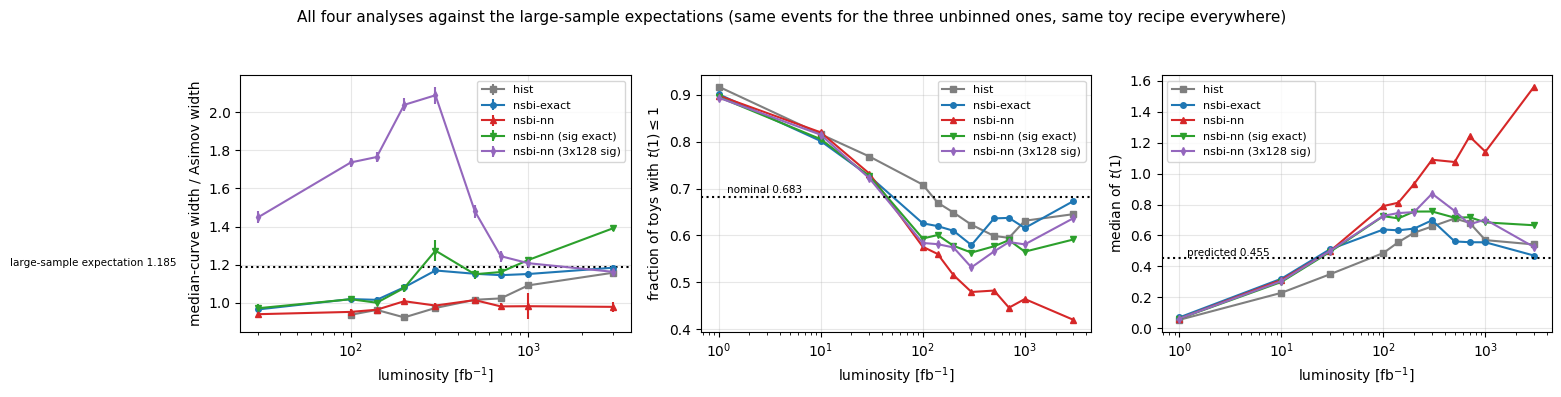

In [6]:
Ls = np.array(LUMIS, dtype=float)
styles = {'hist': ('C7', 's'), 'nsbi-exact': ('C0', 'o'),
          'nsbi-nn': ('C3', '^'), 'nsbi-nn (sig exact)': ('C2', 'v'),
          'nsbi-nn (3x128 sig)': ('C4', 'd')}
fig, axes = plt.subplots(1, 3, figsize=(15.5, 4.0))
for name, (col, mk) in styles.items():
    t = tables[name]
    axes[0].errorbar(Ls, [t[L]['ratio'] for L in LUMIS], yerr=[t[L]['ratio_err'] for L in LUMIS],
                     fmt=mk + '-', color=col, label=name, ms=4)
    axes[1].plot(Ls, [t[L]['cover'] for L in LUMIS], mk + '-', color=col, label=name, ms=4)
    axes[2].plot(Ls, [t[L]['t1'] for L in LUMIS], mk + '-', color=col, label=name, ms=4)
axes[0].axhline(1.185, color='k', ls=':'); axes[0].set_ylabel('median-curve width / Asimov width')
axes[0].text(1.2, 1.19, 'large-sample expectation 1.185', fontsize=7.5)
axes[1].axhline(0.683, color='k', ls=':'); axes[1].set_ylabel('fraction of toys with $t(1) \\leq 1$')
axes[1].text(1.2, 0.69, 'nominal 0.683', fontsize=7.5)
axes[2].axhline(0.455, color='k', ls=':'); axes[2].set_ylabel('median of $t(1)$')
axes[2].text(1.2, 0.47, 'predicted 0.455', fontsize=7.5)
for ax in axes:
    ax.set_xscale('log'); ax.set_xlabel('luminosity [fb$^{-1}$]'); ax.grid(alpha=0.3); ax.legend(fontsize=8)
fig.suptitle('All four analyses against the large-sample expectations (same events for the three unbinned ones, same toy recipe everywhere)', fontsize=11)
fig.tight_layout(rect=[0, 0, 1, 0.93]); plt.show()

## 6. The network error, measured

The unbinned analyses differ only in the ratio, so their differences *are* the network error.
A pointwise-small but *common-mode* error in $\ln r$ is multiplied by the number of events — at
300 fb$^{-1}$ the $\sim$1700-event sum turns sub-percent ratio errors into $O(1)$ shifts of
$-2\ln L$ — displacing and reshaping the Asimov curve while the toys fluctuate around the same
tilt, so the toy family and the Asimov separate.

**The sharpest form of this result:** the two `sig_over_bkg` networks have validation losses
equal to $3\times10^{-5}$ (both 97% of the achievable margin), yet produce *qualitatively
different* pathologies. The Tae-recipe network (16×1024) biases every best fit low (Asimov
$\hat\mu = 0.875$ at all luminosities) and drives the toys' $t(1)$ above its prediction, so the
68% interval covers $\mu = 1$ for only 42-52% of toys at 200-3000 fb$^{-1}$; the 3×128 network
biases high ($\hat\mu = 1.025$) and instead inflates the spread of the toys relative to the
Asimov (median-curve width ratio up to $2.09 \pm 0.04$ at 300 fb$^{-1}$). The direction and
character of an Asimov-vs-toys discrepancy in a network-based analysis is therefore a property of
the *particular trained network*, not of its loss — and not of the statistics of the event
count, which the exact-ratio row shows to be well-behaved.

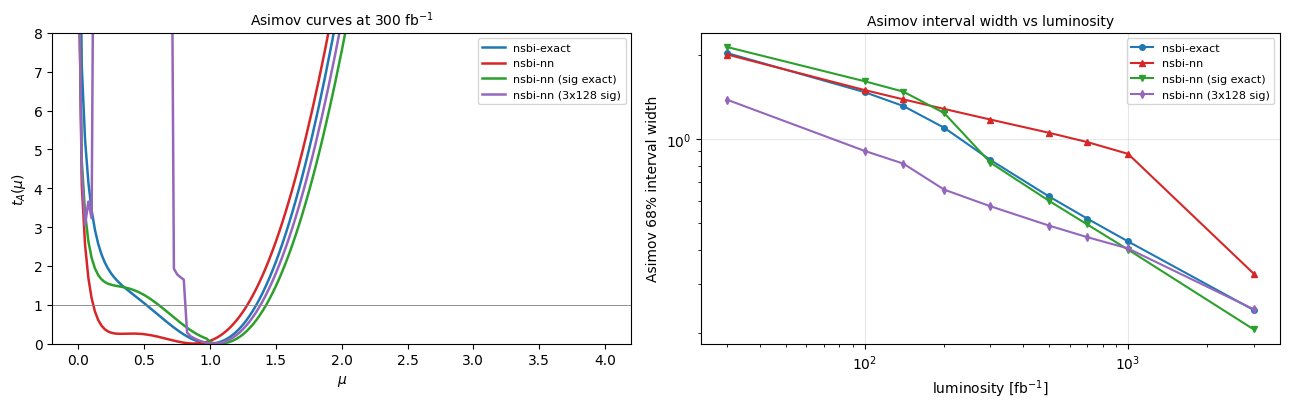

    L mu_A exact  mu_A nn mu_A sig-exact  w_A exact  w_A nn w_A sig-exact
    1      1.000    0.875          1.075        nan     nan           nan
   10      1.000    0.875          1.075        nan     nan           nan
   30      1.000    0.875          1.075      2.030   2.006         2.134
  100      1.000    0.875          1.075      1.469   1.495         1.608
  140      1.000    0.875          1.075      1.311   1.385         1.476
  200      1.000    0.875          1.075      1.096   1.279         1.237
  300      1.000    0.875          1.075      0.839   1.172         0.821
  500      1.000    0.875          1.075      0.621   1.051         0.599
  700      1.000    0.875          1.075      0.517   0.973         0.492
 1000      1.000    0.875          1.075      0.428   0.882         0.400
 3000      1.000    0.875          1.075      0.243   0.328         0.207


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
ax = axes[0]
for name, (col, mk) in styles.items():
    if name == 'hist':
        continue
    t_asim, _ = t_curves(scans[name][300]['nll_asimov'], mu)
    ax.plot(mu, t_asim, '-', color=col, lw=1.8, label=name)
ax.axhline(1.0, color='grey', lw=0.6); ax.set_ylim(0, 8)
ax.set_xlabel('$\\mu$'); ax.set_ylabel('$t_A(\\mu)$'); ax.set_title('Asimov curves at 300 fb$^{-1}$', fontsize=10)
ax.legend(fontsize=8)
ax = axes[1]
for name, (col, mk) in styles.items():
    if name == 'hist':
        continue
    ax.plot(Ls, [tables[name][L]['w_A'] for L in LUMIS], mk + '-', color=col, label=name, ms=4)
ax.set_xscale('log'); ax.set_yscale('log'); ax.grid(alpha=0.3)
ax.set_xlabel('luminosity [fb$^{-1}$]'); ax.set_ylabel('Asimov 68% interval width')
ax.set_title('Asimov interval width vs luminosity', fontsize=10); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()

print(f"{'L':>5} {'mu_A exact':>10} {'mu_A nn':>8} {'mu_A sig-exact':>14} {'w_A exact':>10} {'w_A nn':>7} {'w_A sig-exact':>13}")
for L in LUMIS:
    print(f"{L:>5g} {tables['nsbi-exact'][L]['mu_A']:>10.3f} {tables['nsbi-nn'][L]['mu_A']:>8.3f} "
          f"{tables['nsbi-nn (sig exact)'][L]['mu_A']:>14.3f} {tables['nsbi-exact'][L]['w_A']:>10.3f} "
          f"{tables['nsbi-nn'][L]['w_A']:>7.3f} {tables['nsbi-nn (sig exact)'][L]['w_A']:>13.3f}")

## 7. Tae's committed 300 fb$^{-1}$ scans, and the missing event-count term

**The committed scans cannot be reproduced bit-exactly from the shared material** (the shared
`sig_over_bkg` is a 2ℓ2ν network, §2). The closest faithful configuration — his `sbi_over_bkg`
checkpoint chosen by his own largest-epoch rule, his test events, his statistic (no event-count
term), his toy seeding, plus the `sig_over_bkg` retrained by us with his exact recipe — gives,
under his own plotting convention (median of raw curves), the table below: it **closely
reproduces his committed result** (ratio 0.897 vs his 0.874; Asimov and median widths within a
few percent). The same configuration with the *same-loss* 3×128 `sig_over_bkg` instead gives
ratio 1.38 — the opposite direction. His committed numbers are therefore recovered by his
architecture but not by an equally-well-trained smaller network: the effect belongs to the
particular network, not to the statistics of the analysis.

**Why the no-event-count-term statistic is fragile by construction.** Without the event-count
term, the scan minimum is set entirely by the $\mu$-dependence of the *normalisation* of the
density ratio, and the shape difference between the hypotheses is tiny (ROC area 0.513, §2). The
cells below measure this with the exact ratio: normalising the density with the cross-section
table versus on the event sample — two conventions that differ at the sub-percent level — moves
the Asimov best fit from $\hat\mu = 0.025$ to $\hat\mu = 1.000$. A statistic whose minimum moves
across the whole scan range under a sub-percent convention change cannot locate $\mu$; with the
event-count term included (all scans in §3-§6), the likelihood is anchored and the exact-ratio
Asimov best fit is $\mu = 1.000$ at every luminosity, by construction and in fact.

In [8]:
def raw_median_summary(nll_a, nll_t, mug):
    t_a, mu_a = t_curves(nll_a, mug)
    _, _, w_a = crossing_interval(t_a, mug)
    med_raw = np.median(nll_t, axis=1)
    t_m = med_raw - med_raw.min()
    _, _, w_m = crossing_interval(t_m, mug)
    return mu_a, w_a, float(mug[np.argmin(med_raw)]), w_m

rows = []
ref = os.path.join(ROOT, 'output/reference_tei')
mu_ref = torch.load(f'{ref}/mu_scan.pt', map_location='cpu').numpy().astype(float)
rows.append(("Tae committed (his networks)",) + raw_median_summary(
    torch.load(f'{ref}/nll_scan_asimov.pt', map_location='cpu').numpy().astype(float),
    torch.load(f'{ref}/nll_scan_toys.pt', map_location='cpu').numpy().astype(float), mu_ref))
d = os.path.join(ROOT, 'output/asimov_scan/nsbi_nn_anchor300_taerecipe/lumi_300')
mu_anchor = torch.load(f'{d}/mu_scan.pt', map_location='cpu').numpy()
rows.append(("closest faithful (his sbi + Tae-recipe sig)",) + raw_median_summary(
    torch.load(f'{d}/nll_asimov.pt', map_location='cpu').numpy(),
    torch.load(f'{d}/nll_toys.pt', map_location='cpu').numpy(), mu_anchor))

print('same statistic (no event-count term), same events, same toy seeding, 300 fb^-1:')
print(f"{'configuration':>38} {'Asimov mu_hat':>13} {'Asimov width':>13} {'median mu_hat':>14} {'median width':>13} {'ratio':>6}")
for name, mA, wA, mM, wM in rows:
    print(f'{name:>38} {mA:>13.3f} {wA:>13.3f} {mM:>14.3f} {wM:>13.3f} {wM/wA:>6.3f}')

print('\nfragility of the no-event-count-term statistic (exact ratio, Asimov best fit at 300 fb^-1):')
for tag, rel in [('cross-section-table normalisation', 'nsbi_exact_shapeonly300/lumi_300'),
                 ('sample normalisation', 'nsbi_exact_shapeonly300_samplenorm/lumi_300')]:
    d = os.path.join(ROOT, 'output/asimov_scan', rel)
    a = torch.load(f'{d}/nll_asimov.pt', map_location='cpu').numpy()
    g = torch.load(f'{d}/mu_scan.pt', map_location='cpu').numpy()
    print(f'  {tag:>36}: mu_hat = {g[np.argmin(a)]:.3f}')
print('  (with the event-count term: mu_hat = 1.000 at all 11 luminosities, sections 3-6)')

same statistic (no event-count term), same events, same toy seeding, 300 fb^-1:
                         configuration Asimov mu_hat  Asimov width  median mu_hat  median width  ratio
          Tae committed (his networks)         0.920         1.267          0.760         1.108  0.874
closest faithful (his sbi + Tae-recipe sig)         1.000         1.301          0.920         1.167  0.897

fragility of the no-event-count-term statistic (exact ratio, Asimov best fit at 300 fb^-1):
     cross-section-table normalisation: mu_hat = 0.000
                  sample normalisation: mu_hat = 1.000
  (with the event-count term: mu_hat = 1.000 at all 11 luminosities, sections 3-6)


## 8. Errata in the original study (NSBI rows)

| # | finding | evidence | measured consequence |
|---|---|---|---|
| 1 | the NSBI likelihood omits the event-count (extended Poisson) term | `asimov-aymptotics-check/notebooks/nsbi/fit_asimov_and_toys.ipynb`, NLL cells; Tae's own admission 2026-07-09 | the statistic's minimum is set by the ratio's normalisation, to which the shape gives almost no anchor: the exact-ratio Asimov best fit moves ≈ 0 → 1.000 under a sub-percent normalisation convention change (§7); his committed Asimov best fit 0.920 ≠ 1 sits inside that fragility |
| 2 | the shared `sig_over_bkg` run was trained on the 2ℓ2ν channel (10 features incl. `met`), contradicting `fit-carl-4l.sh` in the same share | `run/h4l/sig_over_bkg/lightning_logs/version_0/config.yaml` | the committed 300 fb$^{-1}$ scans cannot be reproduced bit-exactly from the shared material; retraining his recipe recovers them closely (ratio 0.897 vs 0.874, §7) while a same-loss 3×128 network reverses the direction (1.38) — the effect is network-specific |
| 3 | checkpoints selected by largest epoch number, not best validation loss | `nsbi/carl/utils.py:11-46` | for `sbi_over_bkg`: epoch 67 (val_loss 0.692582) instead of the best epoch; at this task's 10⁻⁴ margins the difference is small but the rule is wrong in general |
| 4 | *resolved non-error*: `sbi_over_bkg` checkpoints labelled 0.69 ≈ ln 2 looked like a failed training (ours did too) | §2 | best achievable loss is 0.692401 — only 7.5·10⁻⁴ below ln 2 (exact-ratio ROC area 0.513); his network captured ~76% of that margin. No training failed; the filename precision hid the learning |
| 5 | median of raw curves without per-toy best-fit subtraction, `torch.median` at even toy counts, single-seed toy block | `notebooks/compare_median_vs_asimov.ipynb` cell 3 | as in the histogram notebook (§7 there); additionally the raw-median interval width is unstable under toy resampling — its `raw_ratio` column jumps between 0.5 and 1.4 across neighbouring luminosities on our sweeps |

**Consequence for the project's headline.** With the exact ratio (network removed), the unbinned
analysis approaches its large-sample behaviour by a few hundred fb$^{-1}$ — same picture as the
histogram, no dramatic NSBI-specific failure (§5). The dramatic effect in Tae's slide 7 is
therefore **not a property of unbinned/NSBI statistics at these event counts**: it is produced by
network ratio error (amplified by the event count) and by the anchor-free no-event-count-term
statistic. Two same-loss networks produce opposite distortions (§6) — with Tae's own architecture
the toys' raw-median interval is again *narrower* than the Asimov (ratio 0.93 at 300 fb$^{-1}$,
his committed 0.874), while an equally-good smaller network makes it *wider* (1.38) — so the
direction of his slide-7 effect is an accident of the particular network. What *is* real, in
every analysis including the histogram and the exact ratio: the slow approach to the 1.185 width
expectation, the mid-luminosity dip of the fraction of toys whose interval contains $\mu = 1$
(~0.6; the interference rate degeneracy studied in `rate_degeneracy.ipynb` /
`bartlett_correction.ipynb`), and the accumulation of toys at $\hat\mu = 0$ at low luminosity.

## 9. Reproduce

```bash
cd /project/atlas/Users/mfernand/SBI_shortcomings
SIF=asimov-aymptotics-check/ml4fp-sbi-tutorial.sif
B="apptainer exec --bind /project/atlas/Users --pwd $PWD --env PYTHONNOUSERSITE=1 $SIF"

# one-time: mirror Tae's checkpoints (no container needed; ~8 GB)
python3 scripts/asimov_scan.py --download-checkpoints --out asimov-aymptotics-check/run/h4l

PKL=asimov-aymptotics-check/run/h4l/sbi_over_bkg/events_numerator_test.pkl
COMMON="--events-pkl $PKL --lumis 1 10 30 100 140 200 300 500 700 1000 3000 \
        --n-toys 2000 --mu-max 4 --mu-points 161 --seed 42"

# the sig_over_bkg network, trained with Tae's exact recipe (condor GPU job, ~2 h)
condor_submit ...  # executable scripts/nsbi_pathB_train.sh, arguments:
# sig_over_bkg_taerecipe $PWD/data/zz4l/ggzz4l_sm/ggzz4l_sig.csv 16 1024 1e-4 500
# (1 GPU + 1 CPU, CARL_NUM_WORKERS=0; full submit text in output/nsbi-pathB/condor/sig_over_bkg_taerecipe.log)
SIG=output/nsbi-pathB/h4l/sig_over_bkg_taerecipe

$B python scripts/asimov_scan.py --analysis nsbi-exact $COMMON --out output/asimov_scan/nsbi_exact_testsplit
$B python scripts/asimov_scan.py --analysis nsbi-nn    $COMMON --sig-checkpoint-dir $SIG --out output/asimov_scan/nsbi_nn_taerecipe
$B python scripts/asimov_scan.py --analysis nsbi-nn    $COMMON --sig-ratio exact --out output/asimov_scan/nsbi_nn_sigexact

# diagnostics for section 7
$B python scripts/asimov_scan.py --analysis nsbi-nn --shape-only --legacy-seed-block \
  --checkpoint-policy largest-epoch --sig-checkpoint-dir $SIG \
  --events-pkl $PKL --lumis 300 --n-toys 200 --mu-max 4 --mu-points 101 --out output/asimov_scan/nsbi_nn_anchor300_taerecipe
$B python scripts/asimov_scan.py --analysis nsbi-exact --shape-only --events-pkl $PKL \
  --lumis 300 --n-toys 8 --mu-max 4 --mu-points 161 --out output/asimov_scan/nsbi_exact_shapeonly300
$B python scripts/asimov_scan.py --analysis nsbi-exact --shape-only --shape-norm sample --events-pkl $PKL \
  --lumis 300 --n-toys 8 --mu-max 4 --mu-points 161 --out output/asimov_scan/nsbi_exact_shapeonly300_samplenorm

# execute this notebook headlessly
$B bash -c "PYTHONPATH=output/pyextra python -m nbconvert --to notebook --execute --inplace notebooks/nsbi_reproduction.ipynb"
```